# 03 - Case Briefs
All ten HVIA cases, solved with data. Each case: **question -> data -> metrics -> chart -> finding -> impact -> recommendation**.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:,.3f}".format)
import analysis as A, modeling as M, visuals as V
from utils import fmt_egp, fmt_pct, fmt_int

In [2]:
import run_pipeline as RP
d = A.load_all()
R = RP.build_results(d)
s = d["sales"]

## Case 1 - Executive Sales & Profitability
*Is growth converting into healthy gross profit across products and channels?*

In [3]:
R['monthly'][['Month','Net_Sales','Gross_Profit','Gross_Margin','MoM','YoY']].tail(14)

,Month,Net_Sales,Gross_Profit,Gross_Margin,MoM,YoY
22,2025-08-01,"13,249,355.630","1,992,141.530",0.150,-0.026,0.142
23,2025-09-01,"10,453,454.100","1,568,056.500",0.150,-0.211,0.096
24,2025-10-01,"10,035,892.240","1,620,892.830",0.162,-0.040,-0.094
25,2025-11-01,"11,339,661.960","1,802,102.880",0.159,0.130,-0.056
26,2025-12-01,"15,635,963.280","2,503,709.510",0.160,0.379,0.071
27,2026-01-01,"10,616,956.410","1,722,416.570",0.162,-0.321,0.020
28,2026-02-01,"9,515,984.180","1,553,435.580",0.163,-0.104,0.094
29,2026-03-01,"12,162,736.980","1,874,987.370",0.154,0.278,0.096
30,2026-04-01,"12,262,285.980","1,912,359.060",0.156,0.008,-0.011
31,2026-05-01,"14,158,935.160","2,135,185.380",0.151,0.155,0.079


In [4]:
pd.concat([R['kpi_fy'].set_index('Fiscal_Year')[['Net_Sales','Gross_Profit','Gross_Margin']], R['kpi_fy'].set_index('Fiscal_Year').Net_Sales.pct_change().rename('Net_YoY')], axis=1)

,Net_Sales,Gross_Profit,Gross_Margin,Net_YoY
Fiscal_Year,,,,
FY24,"129,524,345.150","19,805,835.800",0.153,NaN
FY25,"143,508,088.680","22,018,781.250",0.153,0.108
FY26,"148,305,943.700","23,063,672.850",0.156,0.033


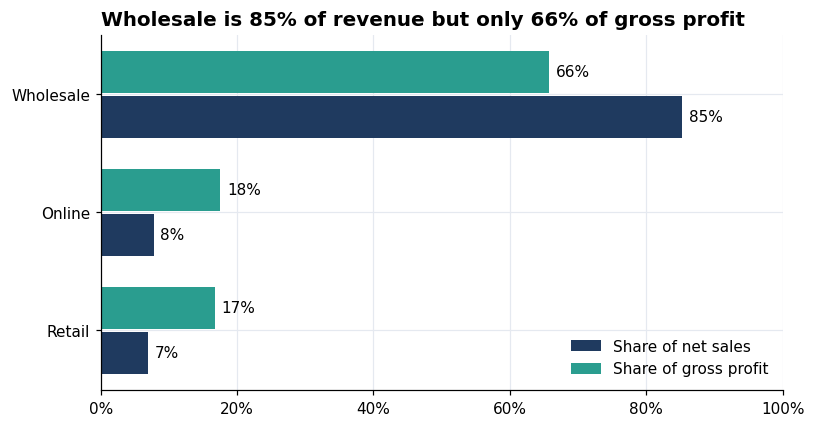

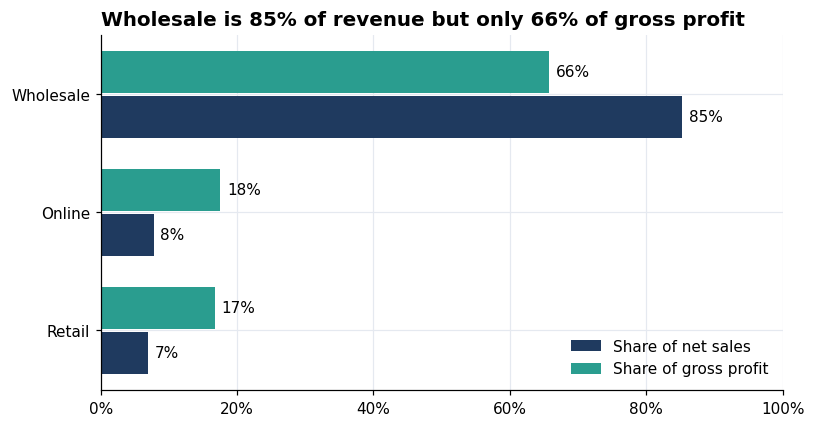

In [5]:
V.channel_share_revenue_vs_profit(R['channel_scorecard'])

In [6]:
R['product_contribution'].groupby('Product_Family')[['Net_Sales','Gross_Profit']].sum().assign(GM=lambda x: x.Gross_Profit / x.Net_Sales)

,Net_Sales,Gross_Profit,GM
Product_Family,,,
Kids Sets,"36,453,088.000","5,274,356.820",0.145
Pajamas/Homewear,"272,328,992.820","41,184,401.860",0.151
Sweatshirts,"76,583,518.110","13,725,982.820",0.179
T-Shirts,"35,972,778.600","4,703,548.400",0.131


**Answer: No - growth is not converting.** Sales +14.5% in two years but margin stuck at ~15.5%, and growth slowed to +3.3% in FY26.
**Why:** 85% of sales are wholesale at 11.9% margin; wholesale discounts avg 32.6% and 10% of wholesale invoices lose money.
**Impact:** every +1pt of wholesale margin = ~EGP 1.25M GP per year (on FY26 wholesale sales).
**Actions:** (1) report and manage gross profit by channel; (2) wholesale discount governance; (3) end non-incremental retail/online promotions.

## Case 2 - Customer 360 & Retention

In [7]:
R['repeat_by_type']

,Customer_Type,Customers,Repeat_Rate,Avg_Orders,AOV,Net_per_Customer,GP_per_Customer
1,Wholesale,1599,0.961,28.109,"7,654.460","215,116.030","25,484.723"
0,Retail,24035,0.835,5.619,495.564,"3,218.966","1,004.294"


In [8]:
R['rfm_segments']

,Segment,Customers,Net_Sales,Gross_Profit,Avg_Orders,AOV,Median_Recency,Opted_In,Customer_Share,Sales_Share
1,At Risk (high frequency),3745,"24,594,351.120","7,175,939.980",10.130,575.537,229.000,0.654,0.156,0.318
2,Champions,3975,"23,750,309.070","7,248,800.160",10.109,533.867,38.000,0.643,0.165,0.307
4,Loyal,1894,"11,565,850.440","3,497,470.540",10.089,546.333,101.000,0.642,0.079,0.149
6,Potential Loyalists,2892,"5,668,412.650","2,017,813.090",4.225,463.976,57.000,0.639,0.120,0.073
0,At Risk,1915,"3,819,620.150","1,369,292.390",4.215,473.619,227.000,0.652,0.080,0.049
3,Hibernating,3997,"3,355,937.050","1,202,392.360",1.805,463.692,229.000,0.627,0.166,0.043
7,Recent / New,3672,"3,035,478.750","1,076,926.530",1.836,446.557,40.000,0.633,0.153,0.039
5,Needs Attention,1945,"1,577,886.650","549,582.500",1.841,440.462,103.000,0.620,0.081,0.020


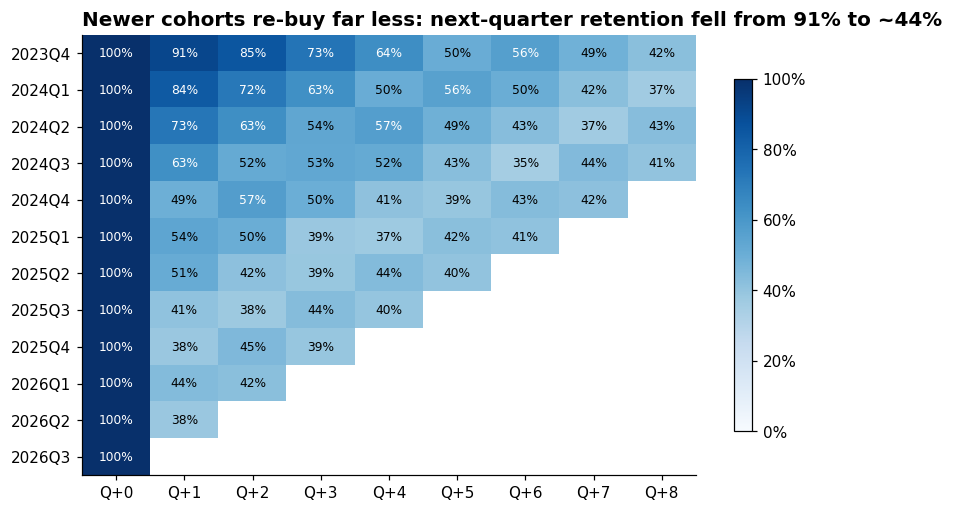

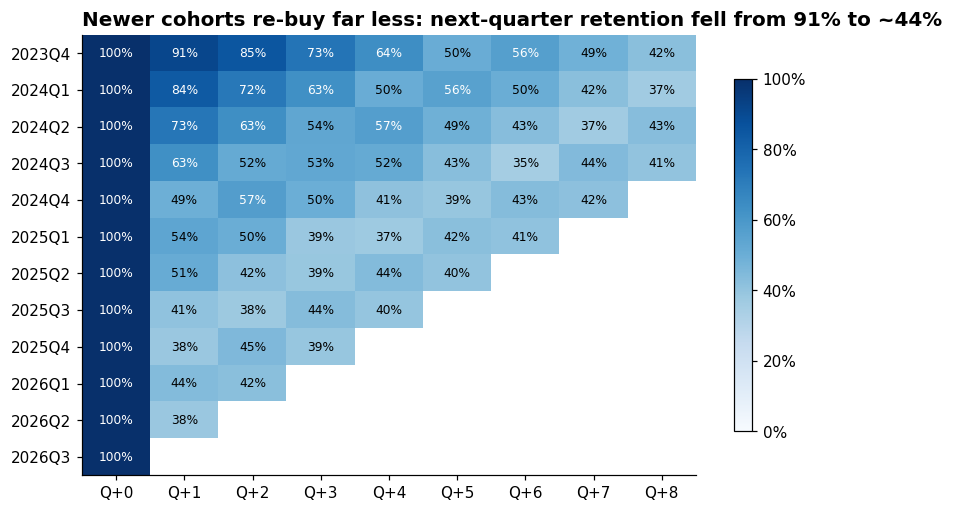

In [9]:
V.cohort_heatmap(R['cohorts'])

In [10]:
R['churn_pool']

,Customer_Type,Customers,Lapsed,Lapsed_Net_Value,Repeat_Lapsed,Lapse_Rate
0,Retail,24035,6625,"22,015,218.730",5489,0.276
1,Wholesale,1599,6,"1,078,345.560",6,0.004


In [11]:
R['hv_governorate'].head(5), R['hv_age'].head(4)

(  Governorate  Top_Decile_Share  All_Retail_Share  Index_vs_Base
 0       Other             0.065             0.060        108.929
 1     Monufia             0.032             0.030        107.712
 2    Dakahlia             0.065             0.061        106.245
 3  Alexandria             0.292             0.280        104.117
 4     Sharqia             0.052             0.051        102.606,
   Age_Band  Top_Decile_Share  All_Retail_Share  Index_vs_Base
 0    25-34             0.399             0.377        105.694
 1    35-44             0.314             0.315         99.622
 2    45-54             0.146             0.153         95.945
 3      55+             0.058             0.060         95.644)

**Findings:** retail repeat rate 83.5% (avg 5.6 orders, AOV EGP 496); wholesale repeat 96% (28 orders, EGP 215K per customer). Champions = 16.5% of customers / 30.7% of sales. **At Risk (high frequency) = 3,745 customers / 31.8% of sales / median 229 days silent / 65% opted-in.** 6,625 retail customers lapsed (>180 days; median inter-purchase gap is 52 days, p90 212) with EGP 22.0M historical sales. Retention at Q+1 fell from 91% to ~44%.
**Recommendation:** win-back journeys for the at-risk segment (WhatsApp/CRM has a CAC of only EGP 7), post-purchase onboarding for new cohorts; value ~EGP 0.12-0.36M GP per year at 5-15% reactivation.

## Case 3 - Branch & Channel Performance

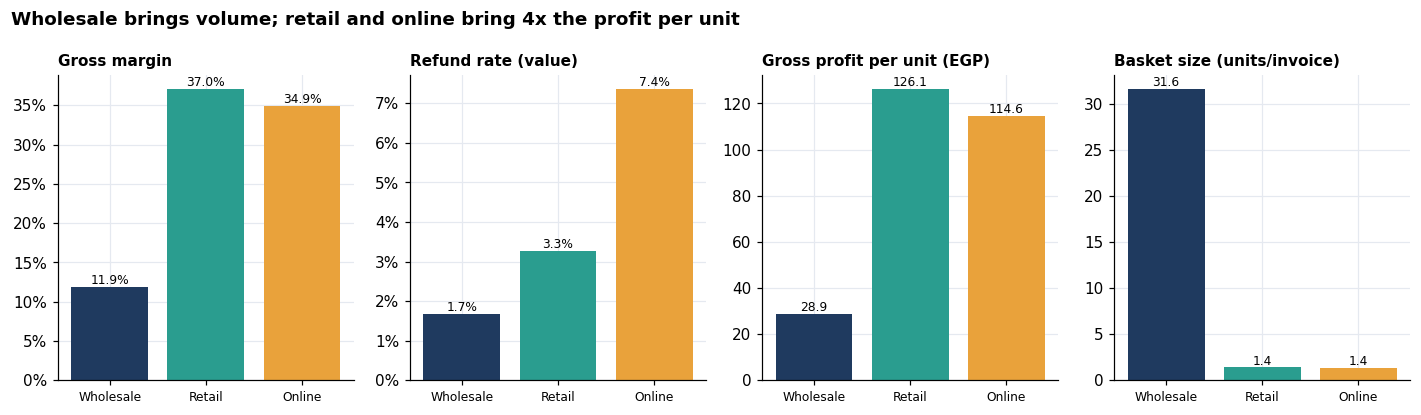

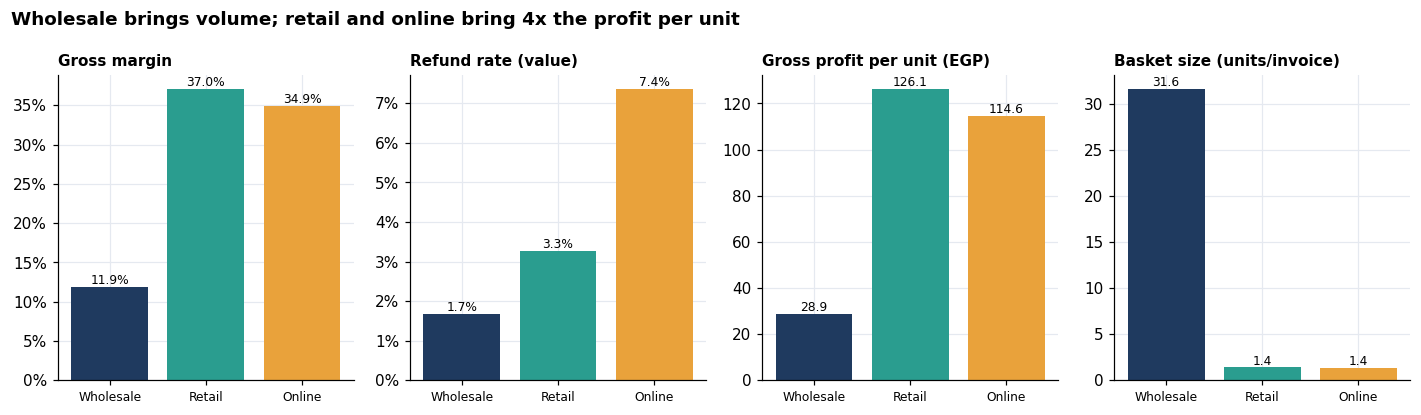

In [12]:
V.channel_scorecard_panels(R['channel_scorecard'])

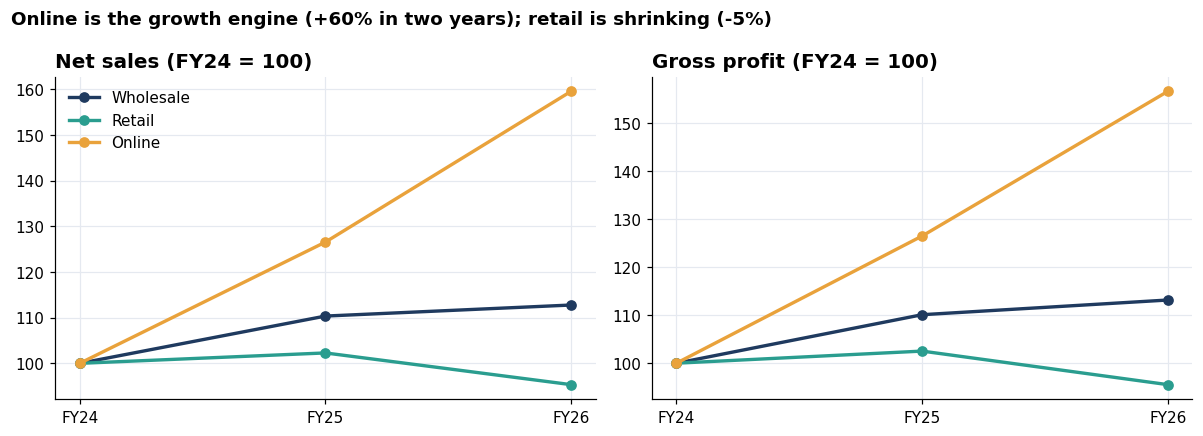

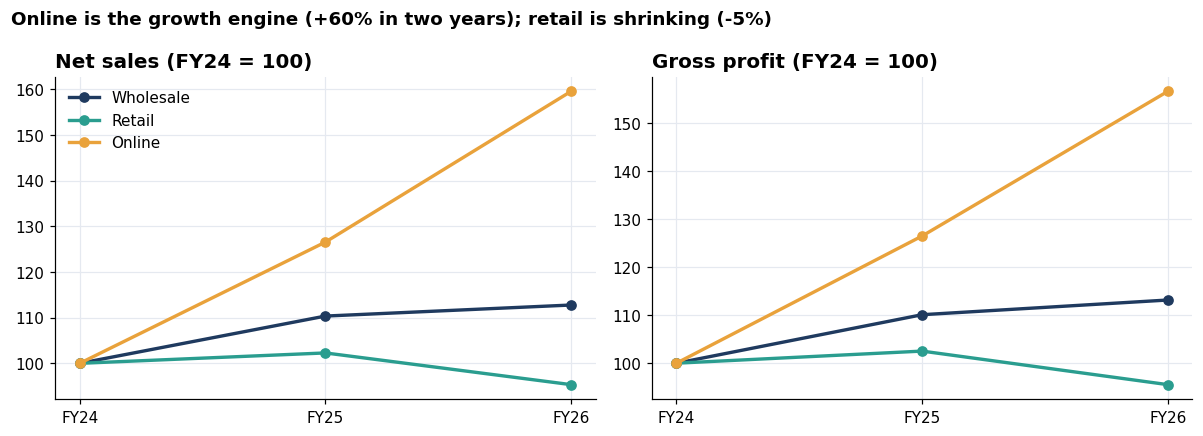

In [13]:
V.channel_growth_lines(R['channel_growth'])

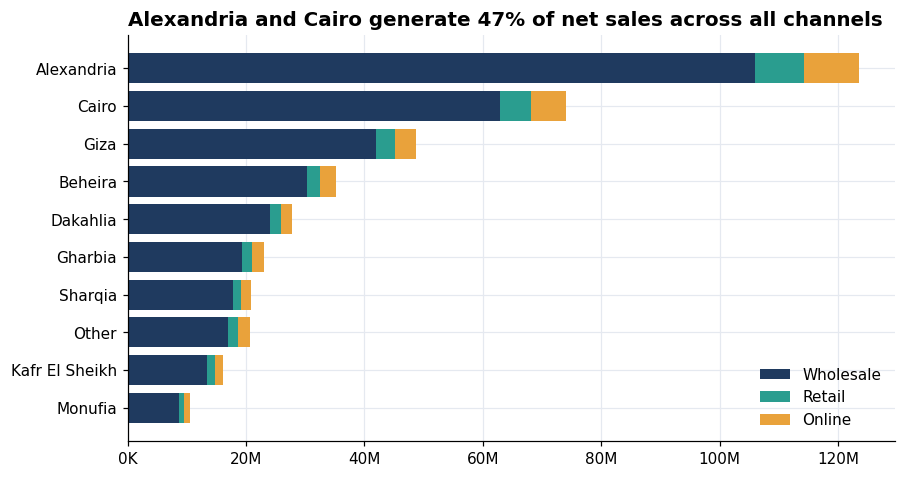

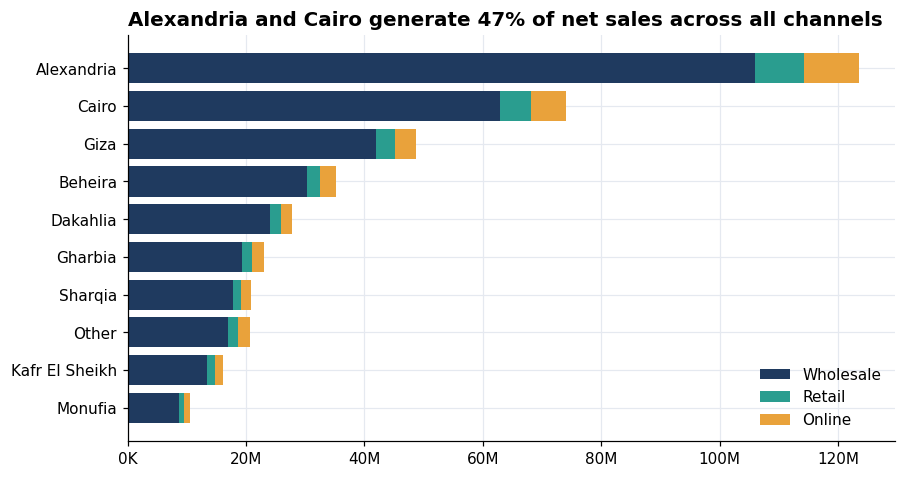

In [14]:
V.geo_stack(R['geo_demand'])

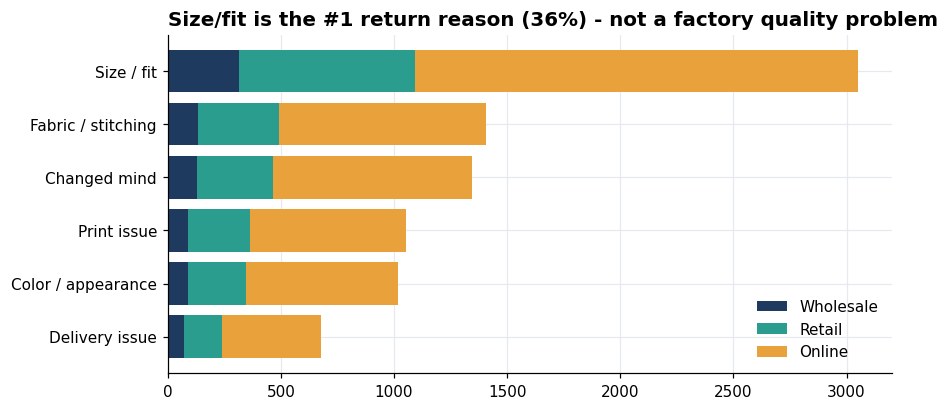

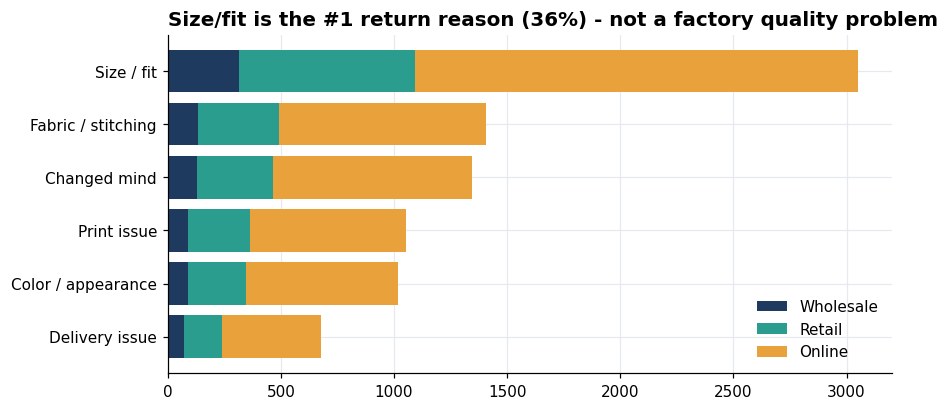

In [15]:
V.return_reason_chart(R['return_reasons'])

**Findings:** Online +60% net sales in two years, wholesale +13%, **retail -4.7%**. Online has the highest return rate (7.7% of lines, refund rate 7.4% of value) vs retail 3.5% and wholesale 1.8%. Basket: wholesale 31.6 units / EGP 7.7K vs ~1.4 units / EGP 460-475 for retail and online. Alexandria (29%) and Cairo (18%) lead demand.
**Underperformance:** the retail store is shrinking; online return rate is 2x retail, driven by size/fit (36% of returns in every channel).
**Recommendations:** shift investment to online but fix size/fit (size guide, fit notes); investigate the retail decline (footfall/range); price wholesale to its true contribution.

## Case 4 - Inventory & Demand Planning

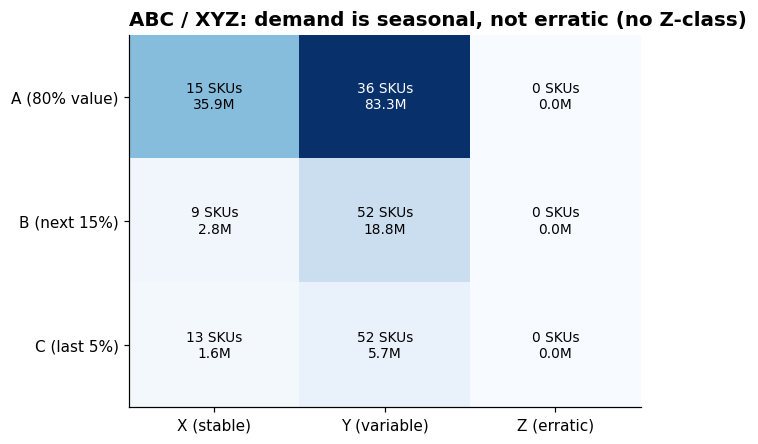

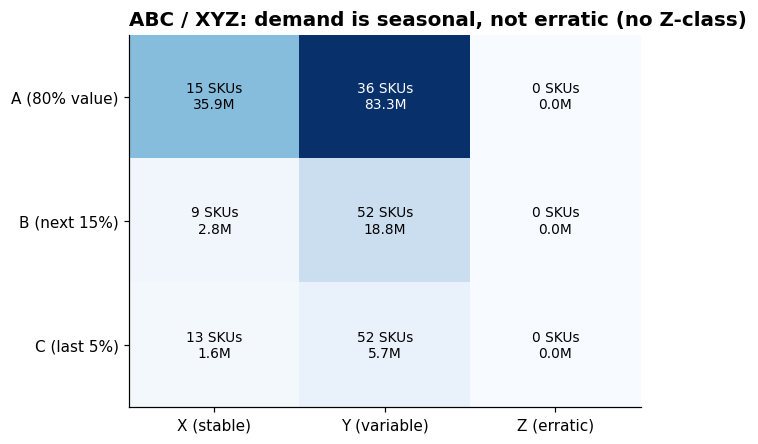

In [16]:
V.abc_xyz_matrix(R['inventory_diag'])

In [17]:
R['inventory_location']

,Location_Name,SKUs,Stock_Value,Excess_Value,Median_Cover_Days,Median_Turns,Stockout_Days_12M,Lost_Units_12M,Overstock_SKUs,Below_ROP_or_Stockout,Excess_Share
0,El-Sharnouby Wholesale Desk,59,"6,430,595.237","1,856,687.060",11.000,24.630,599,"20,083.360",6,36,0.289
1,LEO MODA - Sidi Bishr Store,59,"3,991,966.992","2,662,669.241",118.400,2.965,14,80.590,33,2,0.667
2,LEO MODA Online Store,59,"4,958,511.633","2,959,773.611",112.600,2.867,30,108.510,33,2,0.597


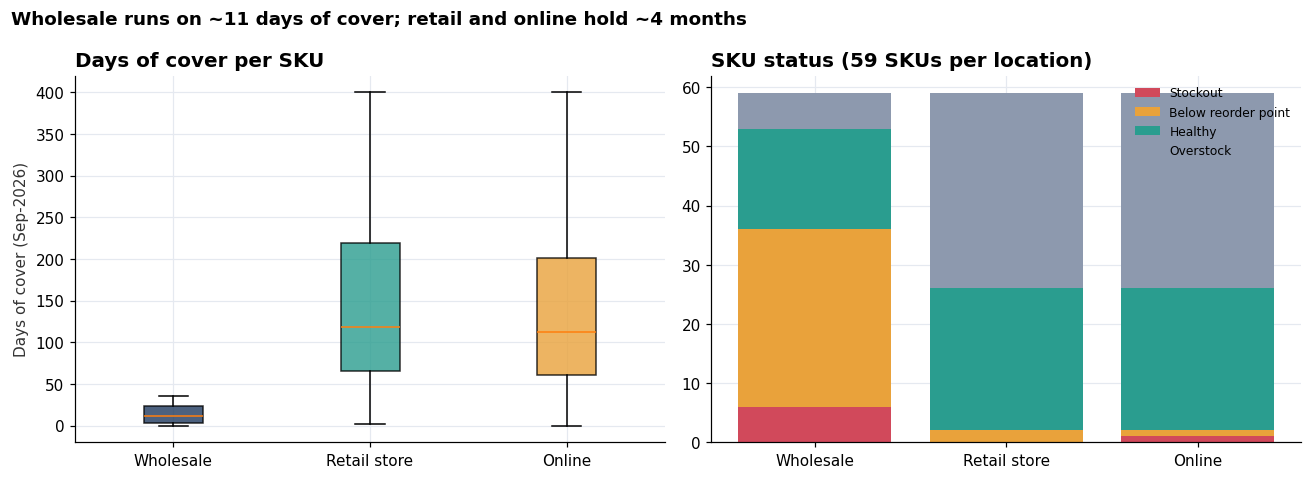

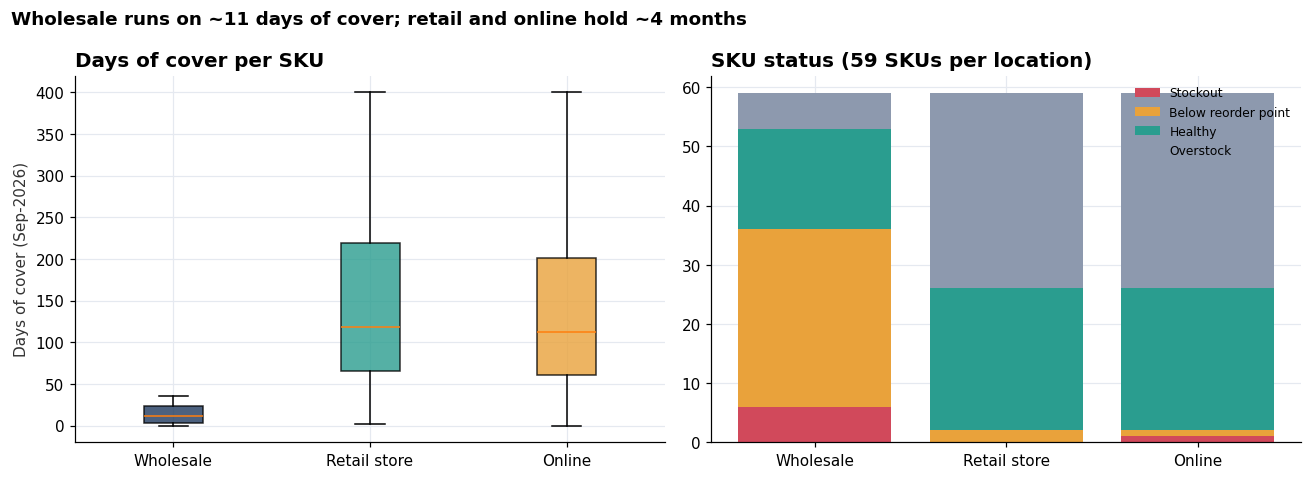

In [18]:
V.inventory_cover_by_location(R['inventory_diag'])

### 30/60/90-day forecast and its backtest

In [19]:
R['backtest_metrics']

,Method,WAPE,Bias,Rows
0,naive3,0.536,-0.043,"1,593.000"
1,seasonal_naive,0.286,-0.047,"1,593.000"
2,si,0.234,-0.033,"1,593.000"
3,si_growth,0.233,-0.028,"1,593.000"


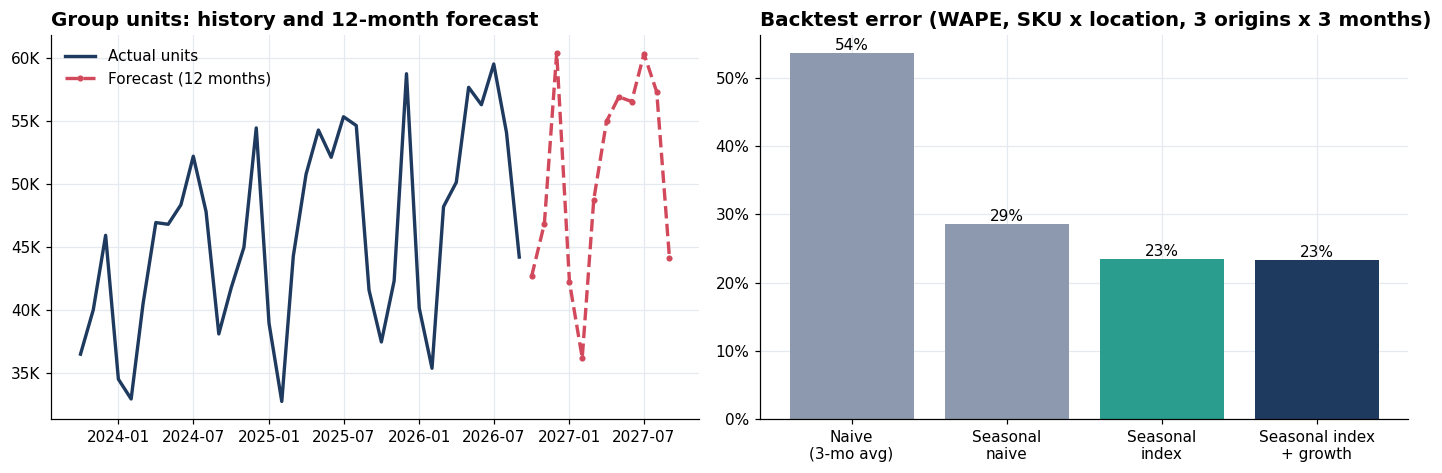

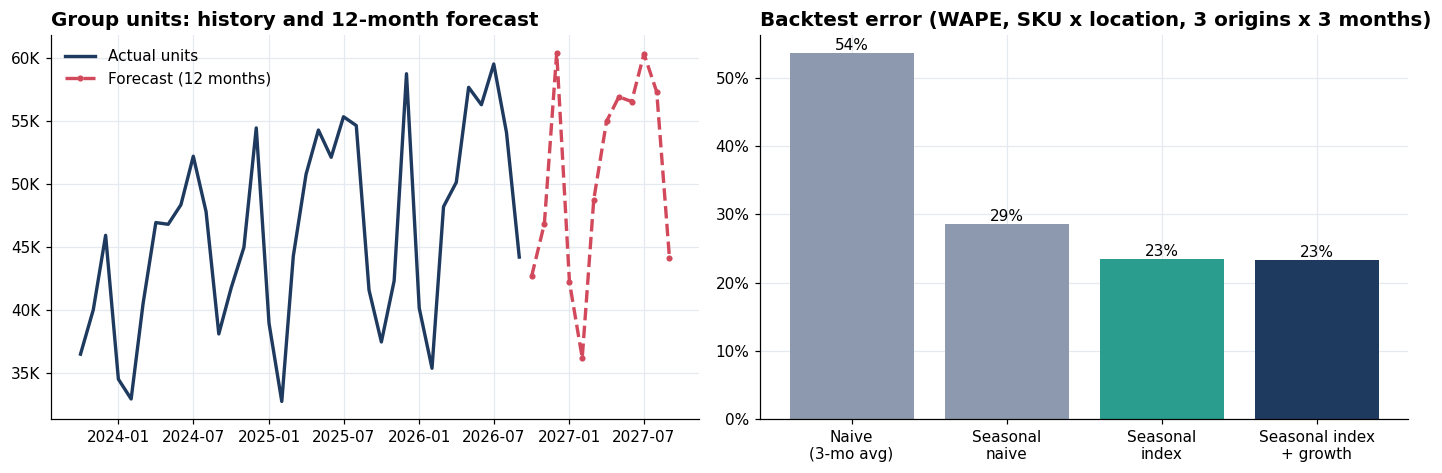

In [20]:
V.forecast_vs_actual(R['history'], R['forecast_12m'], R['backtest'])

In [21]:
R['forecast_horizons'].merge(d['products'][['Product_ID','Product_Name']], on='Product_ID').sort_values('Forecast_90D', ascending=False).head(8)

,Location_ID,Product_ID,M1,M2,M3,Forecast_30D,Forecast_60D,Forecast_90D,Product_Name
150,LOC003,P033,"2,484.680","2,801.941","3,597.160","2,484.680","5,286.621","8,883.781",Boys' sweatshirt-LEO
154,LOC003,P037,"2,396.308","2,702.284","3,469.220","2,396.308","5,098.592","8,567.812",Girls' sweatshirt-Flower
156,LOC003,P039,"2,266.297","2,555.672","3,280.998","2,266.297","4,821.969","8,102.967",Boys' Autumn Pajamas-Spider Man
149,LOC003,P032,"2,197.250","2,477.809","3,181.036","2,197.250","4,675.058","7,856.095",Boys' sweatshirt-blue
155,LOC003,P038,"1,954.765","2,204.362","2,829.983","1,954.765","4,159.128","6,989.111",Boys' Autumn Pajamas-Mickey Mouse
160,LOC003,P043,"1,793.397","2,022.390","2,596.365","1,793.397","3,815.787","6,412.152",Girls' autumn pajamas-Snow White
161,LOC003,P044,"1,635.586","1,844.429","2,367.896","1,635.586","3,480.015","5,847.911",Girls' autumn pajamas-Ice Cream
162,LOC003,P045,"1,582.816","1,784.920","2,291.498","1,582.816","3,367.736","5,659.234",Girls' autumn pajamas-Stitch


**Method:** seasonal-index model per location x season group (summer vs autumn/winter), deseasonalised 6-month level per SKU, damped growth. **Validated** with three rolling origins (Dec-25, Mar-26, Jun-26): SKU x location WAPE **23.3%** vs 28.6% seasonal-naive and 53.6% naive; location-month WAPE ~5%. Bias is small (-2.8%).
### Replenishment logic

In [22]:
R['replenishment'].groupby(['Location_Name','Action']).size().unstack(fill_value=0)

Action,OK,Order,Order now (urgent),Surplus: hold / rebalance
Location_Name,,,,
El-Sharnouby Wholesale Desk,20,11,24,4
LEO MODA - Sidi Bishr Store,10,2,2,45
LEO MODA Online Store,15,0,1,43


In [23]:
R['replenishment'][R['replenishment'].Action.isin(['Order now (urgent)'])].sort_values('Order_Value_EGP', ascending=False)[['Location_Name','Product_Name','Closing_Stock','Model_Reorder_Point','Suggested_Order_Qty','Order_Value_EGP']].head(10)

,Location_Name,Product_Name,Closing_Stock,Model_Reorder_Point,Suggested_Order_Qty,Order_Value_EGP
149,El-Sharnouby Wholesale Desk,Boys' sweatshirt-blue,687,"1,691.302","3,283.000","1,183,433.540"
150,El-Sharnouby Wholesale Desk,Boys' sweatshirt-LEO,45,"1,119.979","3,559.000","1,008,903.223"
156,El-Sharnouby Wholesale Desk,Boys' Autumn Pajamas-Spider Man,258,"2,418.227","4,596.000","833,143.225"
162,El-Sharnouby Wholesale Desk,Girls' autumn pajamas-Stitch,207,"1,218.350","2,653.000","522,354.097"
161,El-Sharnouby Wholesale Desk,Girls' autumn pajamas-Ice Cream,0,"1,258.970","2,956.000","502,723.893"
160,El-Sharnouby Wholesale Desk,Girls' autumn pajamas-Snow White,61,"1,060.694","2,822.000","471,334.488"
155,El-Sharnouby Wholesale Desk,Boys' Autumn Pajamas-Mickey Mouse,56,686.915,"2,565.000","418,898.331"
157,El-Sharnouby Wholesale Desk,Boys' Autumn Pajamas-Loony Tunes,602,"1,381.344","2,171.000","364,341.176"
152,El-Sharnouby Wholesale Desk,Girls' sweatshirt-Fuchsia,143,402.754,952.000,"287,057.693"
122,El-Sharnouby Wholesale Desk,Summer children's boys-Black and orange,140,650.592,"1,148.000","251,644.465"


In [24]:
R['rebalancing'].head(8)

,Product_ID,Product_Name,From,To,Transfer_Units,Value_EGP
0,P008,Summer children's boys-SpongeBob,LEO MODA Online Store,El-Sharnouby Wholesale Desk,223.000,"48,710.297"
1,P003,Summer children's girls-Hello kitty Rose & tur...,LEO MODA Online Store,El-Sharnouby Wholesale Desk,197.000,"42,536.088"
2,P053,PINK panther - بيجامة حريمي صيفي2024,LEO MODA - Sidi Bishr Store,El-Sharnouby Wholesale Desk,163.000,"41,645.227"
3,P014,Boys' summer t-shirt-Black,LEO MODA Online Store,El-Sharnouby Wholesale Desk,198.000,"41,141.592"
4,P018,Boys' summer pajamas-Wear your attitude,LEO MODA - Sidi Bishr Store,El-Sharnouby Wholesale Desk,221.000,"40,767.870"
5,P015,Girls' summer pajamas-Stay cool,LEO MODA Online Store,El-Sharnouby Wholesale Desk,219.000,"37,262.920"
6,P058,OHANA - بيجامة حريمي صيفي 2024,LEO MODA Online Store,El-Sharnouby Wholesale Desk,186.000,"35,995.067"
7,P048,Semon - طقم تيشيرت وشورت اطفال صيفي,LEO MODA - Sidi Bishr Store,El-Sharnouby Wholesale Desk,128.000,"35,805.419"


**Rule:** reorder point = lead-time demand + z(95%) x forecast-error safety stock; order-up-to = demand over lead time + 30-day review + safety stock; surplus = stock above 90-day demand + safety.
**Findings:** wholesale needs orders worth EGP 10.1M (24 SKUs urgent); retail/online hold EGP 6.2M of surplus (policy-based excess EGP 5.6M). Transfers of the same SKU cover only EGP 0.87M of the need, so most wholesale replenishment must be bought/produced - and retail/online buying should be frozen on overstocked SKUs.

## Case 5 - Marketing Effectiveness

In [25]:
R['marketing_platform']

,Platform,Campaigns,Spend,Impressions,Clicks,Orders,Revenue,Avg_Discount,ROAS,CAC,CTR,CVR,CPC,AOV,Spend_Share,Revenue_Share
4,WhatsApp / CRM,42,1546750,64328584,3600635,212023,"103,572,294.180",0.140,66.961,7.295,0.056,0.059,0.430,488.496,0.106,0.576
0,Google,117,3890507,48653120,1833882,80618,"39,952,801.410",0.126,10.269,48.259,0.038,0.044,2.121,495.582,0.267,0.222
3,TikTok,65,2238109,51056892,1160622,21402,"10,915,263.710",0.132,4.877,104.575,0.023,0.018,1.928,510.011,0.153,0.061
2,Meta,153,5437904,105156585,1984136,46851,"23,742,710.370",0.123,4.366,116.068,0.019,0.024,2.741,506.771,0.373,0.132
1,Influencer,43,1470706,11919021,147463,3120,"1,558,887.600",0.108,1.060,471.380,0.012,0.021,9.973,499.643,0.101,0.009


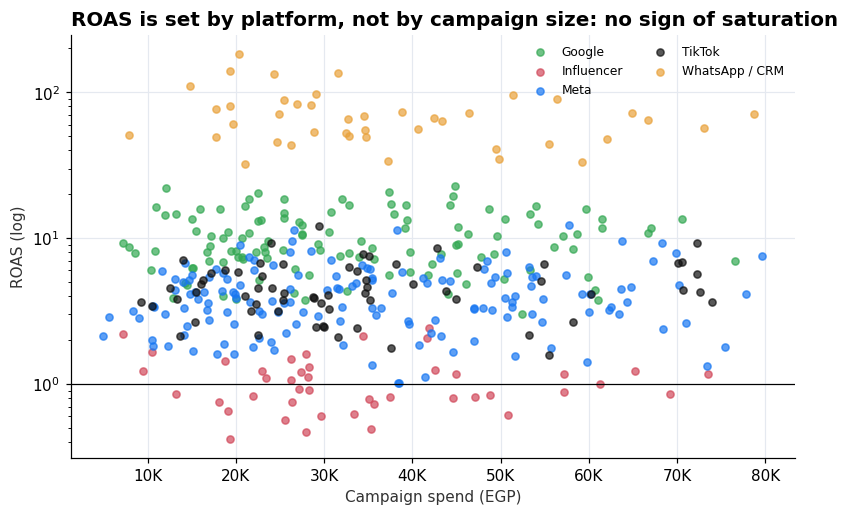

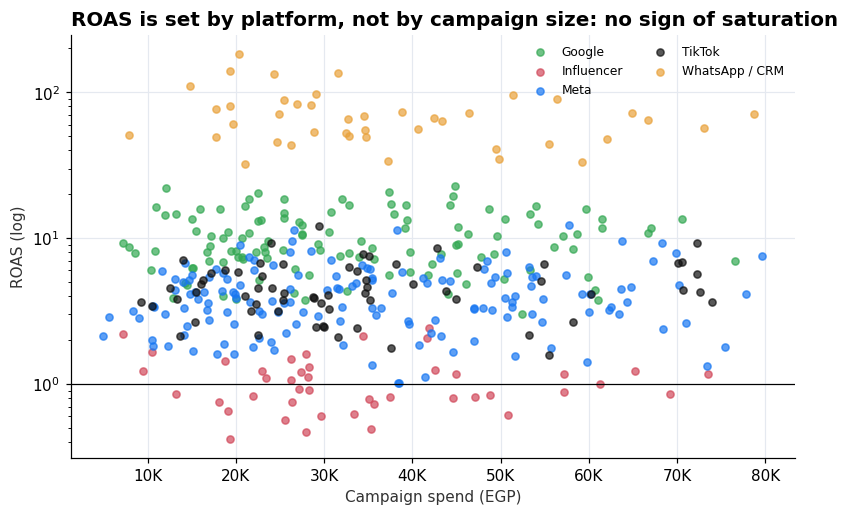

In [26]:
V.campaign_scatter(R['marketing_campaigns'])

In [27]:
R['marketing_campaigns'].query("Outlier != 'Normal'")[['Campaign_ID','Platform','Product_ID','Spend_EGP','ROAS','Outlier']].sort_values('ROAS')

,Campaign_ID,Platform,Product_ID,Spend_EGP,ROAS,Outlier
260,CMP0261,Influencer,P056,19329,0.420,Underperformer
150,CMP0151,Meta,P019,38455,1.014,Underperformer
318,CMP0319,Meta,P041,38410,1.022,Underperformer
178,CMP0179,Meta,P059,41414,1.119,Underperformer
357,CMP0358,Meta,P056,73354,1.323,Underperformer
366,CMP0367,TikTok,P045,55443,1.574,Underperformer
419,CMP0420,TikTok,P029,37570,1.752,Underperformer
208,CMP0209,Influencer,P037,41942,2.408,Star
117,CMP0118,Google,P004,52468,3.020,Underperformer
239,CMP0240,Meta,P033,26640,11.295,Star


In [28]:
R['marketing_product_family'].sort_values('ROAS', ascending=False).head(8)[['Platform','Product_Family','Spend','ROAS','CAC']]

,Platform,Product_Family,Spend,ROAS,CAC
18,WhatsApp / CRM,Sweatshirts,114897,135.089,5.437
19,WhatsApp / CRM,T-Shirts,66728,64.555,5.539
17,WhatsApp / CRM,Pajamas/Homewear,1279945,61.564,7.590
16,WhatsApp / CRM,Kids Sets,85180,58.054,8.336
0,Google,Kids Sets,319247,13.369,39.946
2,Google,Sweatshirts,548339,12.734,58.646
3,Google,T-Shirts,538143,10.183,46.078
1,Google,Pajamas/Homewear,2484778,9.346,48.157


In [29]:
pd.DataFrame(R['reallocation']).T

,budget_shifted,revenue_lost_reported,revenue_gained_reported,net_revenue_reconciled,net_gross_profit
low,"1,167,152.100","3,698,094.738","2,996,460.106","-127,346.686","-45,717.460"
base,"1,167,152.100","3,698,094.738","5,992,920.212","791,714.788","284,225.609"
high,"1,167,152.100","3,698,094.738","11,985,840.423","8,287,745.685","2,975,300.701"


In [30]:
R['attribution']

{'attributed_revenue': np.float64(179741957.26999998),
 'online_net_sales': np.float64(32629574.45),
 'non_wholesale_net_sales': np.float64(61977261.849999994),
 'overclaim_vs_online': np.float64(5.508559651779338),
 'haircut_factor_online': np.float64(0.18153565781519435),
 'haircut_factor_non_wholesale': np.float64(0.3448124343995022),
 'attributed_orders': 364014,
 'online_invoices': 71559}

**Findings:** ROAS: CRM 67x, Google 10.3x, TikTok 4.9x, Meta 4.4x, Influencer 1.06x; CAC EGP 7 / 48 / 105 / 116 / 471. Spend-to-revenue elasticity is ~1.0 on every platform, so there is **no evidence of saturation** (and none that more budget needs less efficiency). 14 campaigns are outliers (8 underperformers, including 4 Meta campaigns at ROAS 1.0-1.3, and 6 stars).
**Caveat:** attributed revenue is 5.5x online sales; on a reconciled basis Meta/TikTok may be below the 2.8x gross-profit break-even.
**Recommendation:** (1) cut 50% of Influencer; (2) pause the 7 campaigns below 2x ROAS; (3) give Google +30% budget; (4) run holdout/incrementality tests on Meta and TikTok before any scale-up. Expected gain is small and uncertain (EGP -0.02M to +1.0M GP/yr) - an efficiency lever, not a growth engine.

## Case 6 - Factory Production & Bottlenecks

In [31]:
R['line_scorecard']

,Line_ID,Orders,Planned,Produced,Good,Rejected,Efficiency,Avg_Delay_Days,Delayed_Share,Overtime_Hours,Avg_Throughput_Day,Avg_Cycle_Days,Plan_Attainment,Reject_Rate,Overtime_per_Order
0,LINE-01,525,1468076,1333223,1300233,32990,82.184,0.851,0.145,"3,436.200",169.447,17.349,0.908,0.025,6.545
1,LINE-02,501,1359061,1234906,1204223,30683,82.368,0.745,0.144,"3,657.200",161.417,17.259,0.909,0.025,7.300
2,LINE-03,489,1356528,1229878,1199696,30182,82.135,0.863,0.147,"3,291.600",164.549,17.223,0.907,0.025,6.731
3,LINE-04,502,1383773,1266085,1234125,31960,82.465,1.054,0.203,"3,685.800",160.813,17.699,0.915,0.025,7.342
4,LINE-05,483,1330038,1203628,1173203,30425,81.881,0.954,0.176,"3,555.100",160.794,17.093,0.905,0.025,7.360


In [32]:
R['line_significance']

,Line_ID,Delayed_Share,Rest_Delayed_Share,p_value
0,LINE-01,0.145,0.168,0.233
1,LINE-02,0.144,0.168,0.220
2,LINE-03,0.147,0.167,0.332
3,LINE-04,0.203,0.153,0.007
4,LINE-05,0.176,0.160,0.421


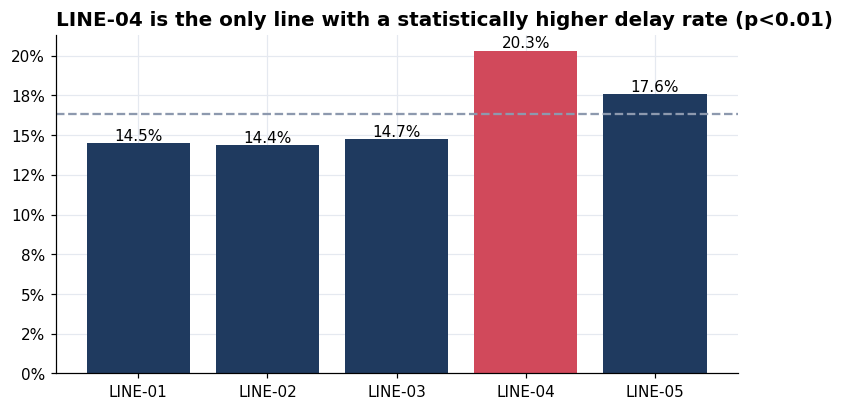

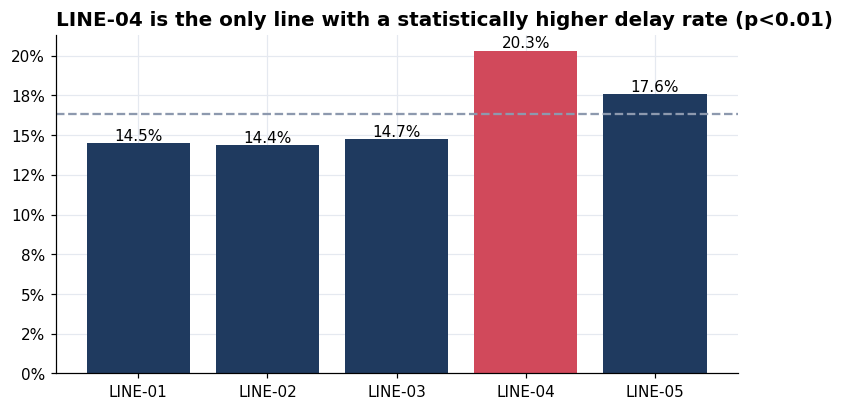

In [33]:
V.line_delay_chart(R['line_scorecard'], R['line_significance'])

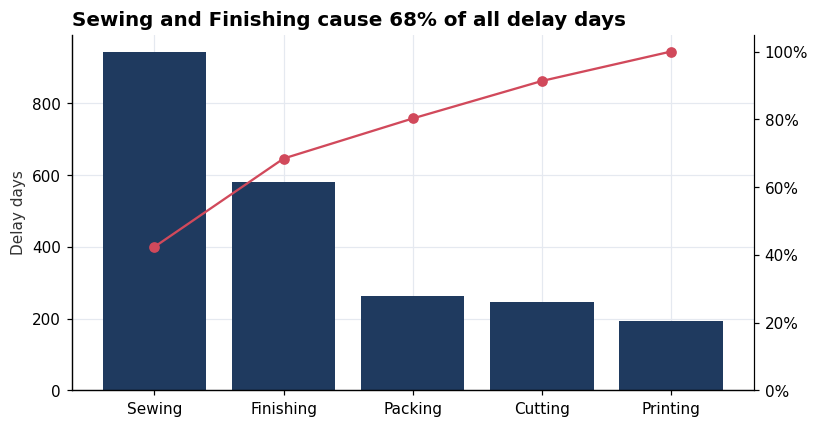

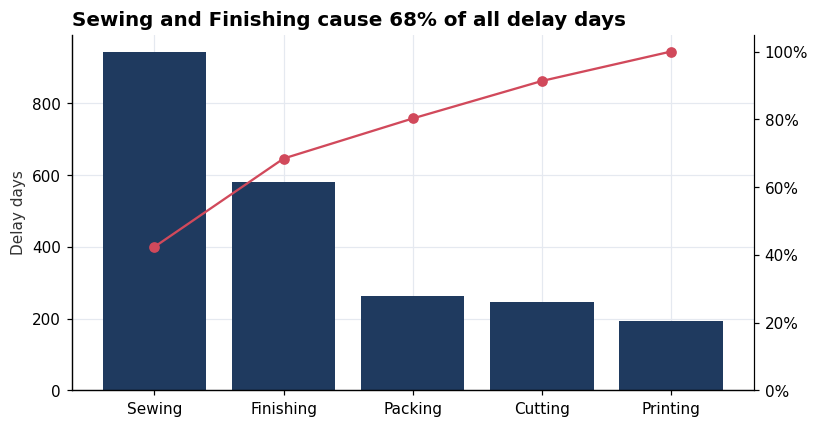

In [34]:
V.bottleneck_pareto_chart(R['bottleneck'])

In [35]:
R['line_bottleneck']

Primary_Bottleneck,Cutting,Finishing,Packing,Printing,Sewing
Line_ID,,,,,
LINE-01,39,92,42,35,239
LINE-02,58,124,51,6,134
LINE-03,42,102,45,31,202
LINE-04,35,124,61,92,217
LINE-05,73,140,65,30,153


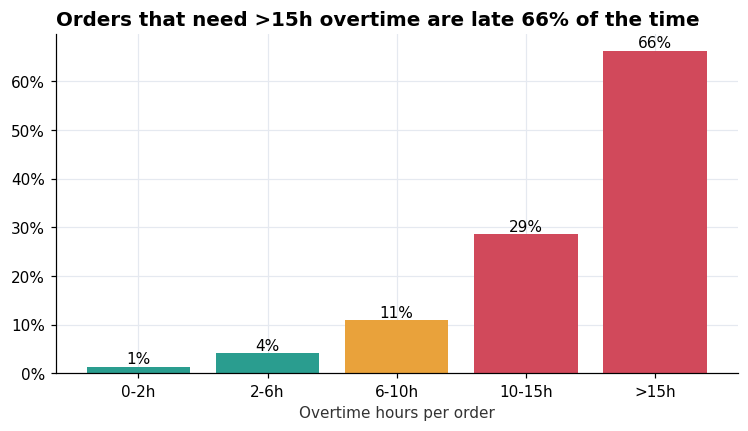

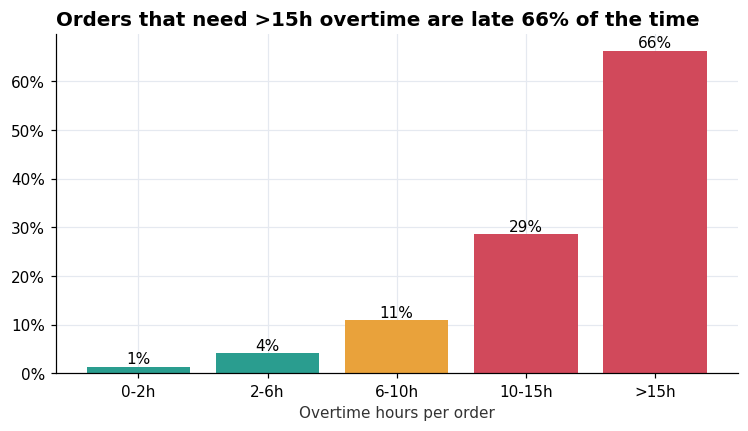

In [36]:
V.overtime_delay_chart(R['overtime'])

In [37]:
R['production_monthly'][['Month','Produced','Planned','Efficiency','Delayed_Share','Hub_Reported_Garments','Capacity_Util_Reported']].tail(6)

,Month,Produced,Planned,Efficiency,Delayed_Share,Hub_Reported_Garments,Capacity_Util_Reported
30,2026-04-01,223909,249285,80.286,0.264,74623,0.574
31,2026-05-01,200259,216106,84.437,0.098,105505,0.812
32,2026-06-01,229503,253412,82.362,0.071,81847,0.630
33,2026-07-01,160465,174588,83.762,0.132,79393,0.611
34,2026-08-01,222018,243402,82.992,0.153,95683,0.736
35,2026-09-01,155287,171170,81.511,0.082,107063,0.824


**Findings:** plan attainment 90.5-91.5% on all lines; reject rate 2.5% everywhere; efficiency ~82%. Differences are in **delay**: LINE-04 20.3% delayed (p=0.008). Sewing (42%) + Finishing (26%) = 68% of delay days; those delayed orders run 73-75% efficiency with ~14-15h overtime. Reported capacity utilisation averages 70% (peaks 113%) against the public 5,000 pieces/day; order-based throughput implies 134% - an unreconciled gap.
**Priorities:** (1) Sewing/Finishing balancing and skill cover on LINE-04; (2) cap overtime (an overtime >15h order is late 66% of the time - overtime is a symptom, not a cure); (3) reconcile production-order volumes with the hub's reported output.

## Case 7 - Quality, Returns & Cost of Poor Quality

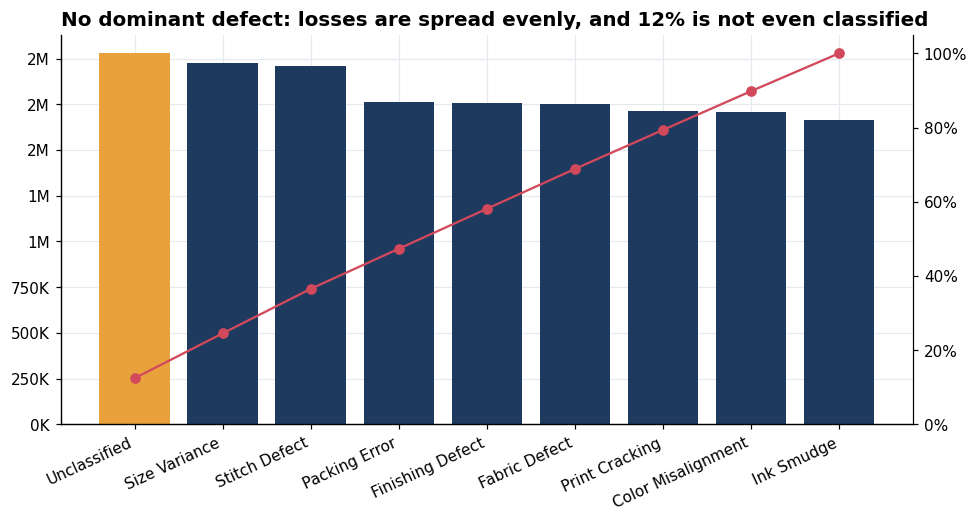

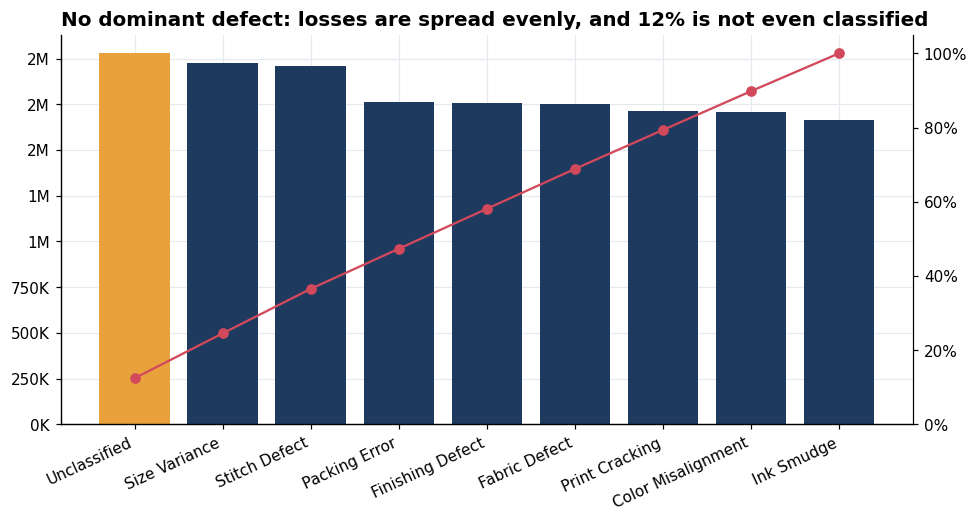

In [38]:
V.defect_pareto_chart(R['defect_pareto'])

In [39]:
R['stage_summary']

,Stage,Inspected,Rejected,Loss,Reject_Rate
0,Cutting,635851,15365,"2,810,109.570",0.024
3,Finishing,626258,15229,"2,791,198.600",0.024
5,Sewing,625472,14864,"2,699,704.480",0.024
1,Fabric,625790,14880,"2,695,718.120",0.024
2,Final,622825,14839,"2,665,239.300",0.024
4,Printing,597182,14647,"2,660,944.060",0.025


In [40]:
R['root_cause']

,Root_Cause,Inspected,Rejected,Loss,Reject_Rate,Loss_Share
0,Curing temperature,479144,11951,"2,181,639.290",0.025,0.134
7,Process variation,457015,11543,"2,145,308.030",0.025,0.131
1,Handling / packing,454812,11267,"2,047,728.110",0.025,0.125
5,Operator method,446094,11243,"2,040,608.520",0.025,0.125
2,Machine calibration,452968,11283,"2,031,247.460",0.025,0.124
6,Pattern / measurement,440347,11158,"2,018,582.400",0.025,0.124
4,No significant issue,583153,11005,"1,994,872.650",0.019,0.122
3,Material variation,419845,10374,"1,862,927.670",0.025,0.114


In [41]:
R['quality_return_link']

,Return_Reason,Matched_Defects,Products,Pearson_r,p_value
0,Fabric / stitching,"Fabric Defect, Stitch Defect, Finishing Defect",59,0.329,0.011
1,Print issue,"Print Cracking, Ink Smudge, Color Misalignment",59,0.154,0.246


In [42]:
R['copq']

,Type,Component,EGP,Share,Pct_of_Gross_Profit
0,Internal failure,QC rejects (inspection loss),"16,322,914.130",0.803,0.252
1,Internal failure,Print rework cost,"795,587.650",0.039,0.012
2,Internal failure,Consumables wasted on rejected prints,"693,071.423",0.034,0.011
3,External failure,Refunds on quality-related returns,"2,509,899.210",0.124,0.039


In [43]:
R['product_quality_priority']

,Product_ID,Product_Name,Product_Family,QC_Reject_Rate,QC_Loss_EGP,Quality_Return_Rate,Priority_Score
4,P005,Summer children's boys-Black and orange,Pajamas/Homewear,0.026,"413,272.910",0.015,0.890
7,P008,Summer children's boys-SpongeBob,Pajamas/Homewear,0.025,"590,840.440",0.013,0.873
28,P029,Girls' pajamas-Daylife+kuromi,Pajamas/Homewear,0.025,"377,453.280",0.014,0.839
31,P032,Boys' sweatshirt-blue,Sweatshirts,0.025,"672,229.980",0.014,0.839
36,P037,Girls' sweatshirt-Flower,Sweatshirts,0.024,"865,884.340",0.016,0.831
33,P034,Boys' sweatshirt-black and white,Sweatshirts,0.026,"326,710.700",0.012,0.822
49,P050,Yellow - طقم تيشيرت وشورت اطفال صيفي,Kids Sets,0.029,"293,346.210",0.015,0.805
50,P051,Ice cream - بيجامة حريمي صيفي2024,Pajamas/Homewear,0.024,"686,897.300",0.013,0.788
8,P009,Boys' summer t-shirt-Aubergine,T-Shirts,0.027,"246,732.510",0.016,0.737
23,P024,Boys' summer pajamas-Mickey,Pajamas/Homewear,0.025,"284,966.480",0.011,0.729


**Findings:** QC loss EGP 16.3M; Pareto is flat (top defect 12%); every stage rejects 2.4%; root cause 'curing temperature' / 'process variation' / 'handling' each ~12-13%; 12.4% of loss is unclassified and **1,612 rejecting inspections are coded 'No significant issue'** (coding is unreliable). Customer link: fabric/stitching defects correlate with matching returns at product level (r=0.33, p=0.011); print defects do not (r=0.15). Cost of poor quality EGP 20.3M = 31% of gross profit (80% internal QC loss).
**Corrective-action priorities:** (1) fix defect/root-cause coding first - cannot manage what is not classified; (2) a *systemic* process-control programme (curing temperature, calibration, pattern) rather than a single-defect fix; (3) target the 10 priority products; (4) size/fit returns (36%) are a product-information issue.

## Case 8 - Printing Performance & Downtime

In [44]:
R['machines'][['Machine_ID','Batches','Yield','Reject_Rate','Reprint_Rate','Cost_per_Good_Unit','Downtime_Hours','Unplanned_Share','Hours_per_Event','Priority_Score']]

,Machine_ID,Batches,Yield,Reject_Rate,Reprint_Rate,Cost_per_Good_Unit,Downtime_Hours,Unplanned_Share,Hours_per_Event,Priority_Score
2,PR-M03,386,0.970,0.030,0.020,4.773,553.500,0.767,2.460,3.704
0,PR-M01,395,0.974,0.026,0.017,4.771,540.600,0.819,2.216,0.922
1,PR-M02,378,0.974,0.026,0.017,4.680,591.300,0.820,2.394,0.196
3,PR-M04,371,0.974,0.026,0.018,4.673,500.800,0.845,2.044,-2.126
4,PR-M05,370,0.974,0.026,0.018,4.655,491.700,0.722,2.119,-2.695


In [45]:
R['machine_significance']

,Machine_ID,Reject_Rate,Rest_Reject_Rate,p_value
0,PR-M01,0.026,0.027,0.000
1,PR-M02,0.026,0.027,0.000
2,PR-M03,0.030,0.026,0.000
3,PR-M04,0.026,0.027,0.000
4,PR-M05,0.026,0.027,0.000


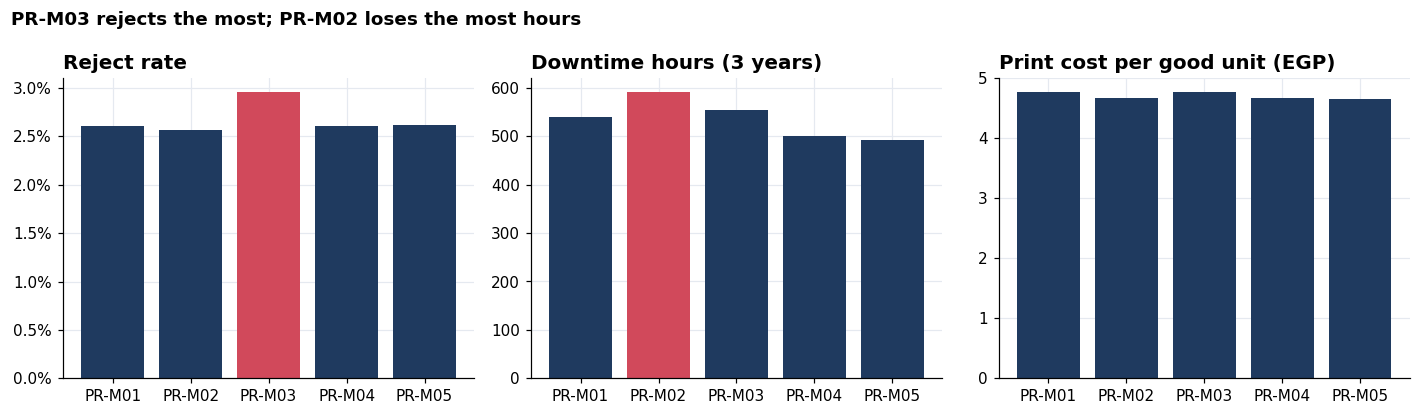

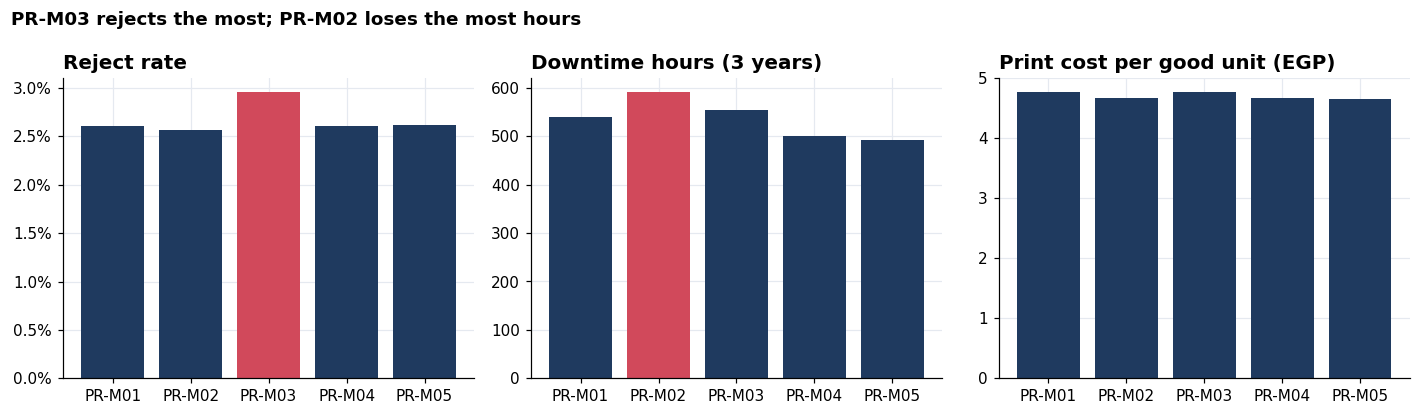

In [46]:
V.printer_priority_chart(R['machines'])

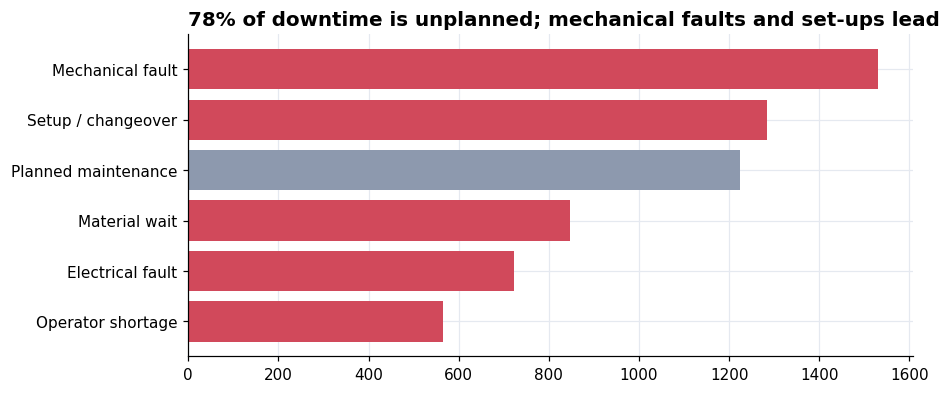

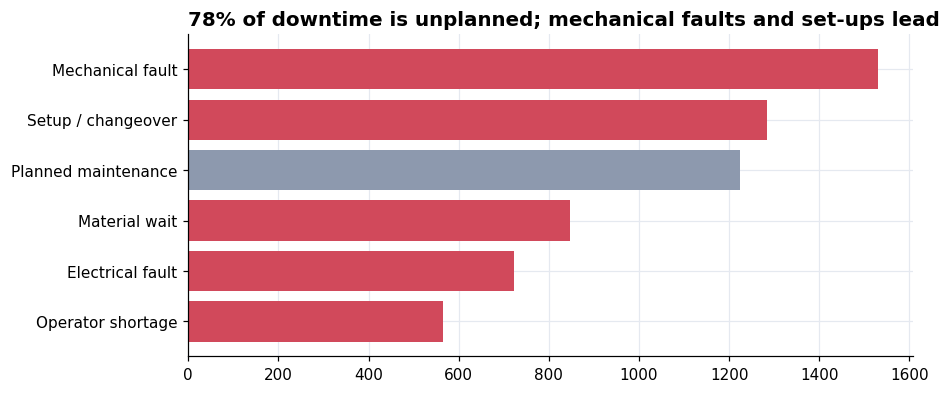

In [47]:
V.downtime_reason_chart(R['downtime_reasons'])

In [48]:
R['machine_link']

{'machine_months': 180,
 'pearson_r': np.float64(-0.21345911329663206),
 'p_value': np.float64(0.004012989171778963)}

**Findings:** yield 97.0-97.4% on all machines; **PR-M03: 3.0% reject vs 2.6%** (p<0.001), highest reprint rate and cost per good unit; **PR-M02: 591 downtime hours**, the most. Unplanned causes are 80% of all downtime hours; mechanical faults (25%) and set-up/changeover (21%) lead; material wait is 14% of hours. Machine-months with more downtime have lower yield (r=-0.21, p=0.004).
**Maintenance priorities:** 1) PR-M03 (quality-driven: calibration/curing check), 2) PR-M02 (mechanical reliability, 82% unplanned), 3) PR-M01; SMED/changeover reduction on all.

## Case 9 - Supply Chain & Materials

In [49]:
R['suppliers'][['Supplier_ID','Category','Contracted','Spend_Share','OTD','OTIF','Avg_Days_Late','Lead_Time','Promised_Lead_Time','Reject_Rate']]

,Supplier_ID,Category,Contracted,Spend_Share,OTD,OTIF,Avg_Days_Late,Lead_Time,Promised_Lead_Time,Reject_Rate
8,SUP09,Trims,No,0.086,0.346,0.173,3.619,14.720,11.100,0.019
3,SUP04,Printing Consumables,Yes,0.074,0.399,0.235,2.918,14.680,11.762,0.017
11,SUP12,Fabric,Yes,0.070,0.668,0.396,0.544,12.144,11.601,0.018
5,SUP06,Packaging,Yes,0.082,0.679,0.394,0.481,11.910,11.429,0.017
7,SUP08,Trims,No,0.092,0.690,0.434,0.491,11.649,11.158,0.018
6,SUP07,Packaging,Yes,0.096,0.693,0.400,0.496,12.110,11.615,0.018
0,SUP01,Packaging,No,0.069,0.703,0.412,0.477,11.573,11.097,0.017
2,SUP03,Fabric,No,0.094,0.722,0.399,0.364,11.828,11.464,0.017
4,SUP05,Fabric,No,0.083,0.724,0.411,0.397,11.943,11.545,0.018
10,SUP11,Trims,Yes,0.087,0.725,0.387,0.446,11.862,11.416,0.019


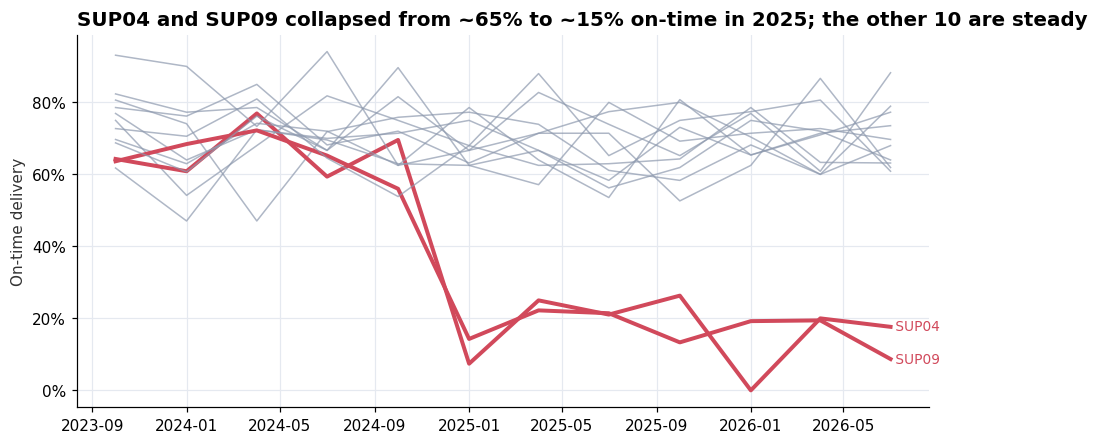

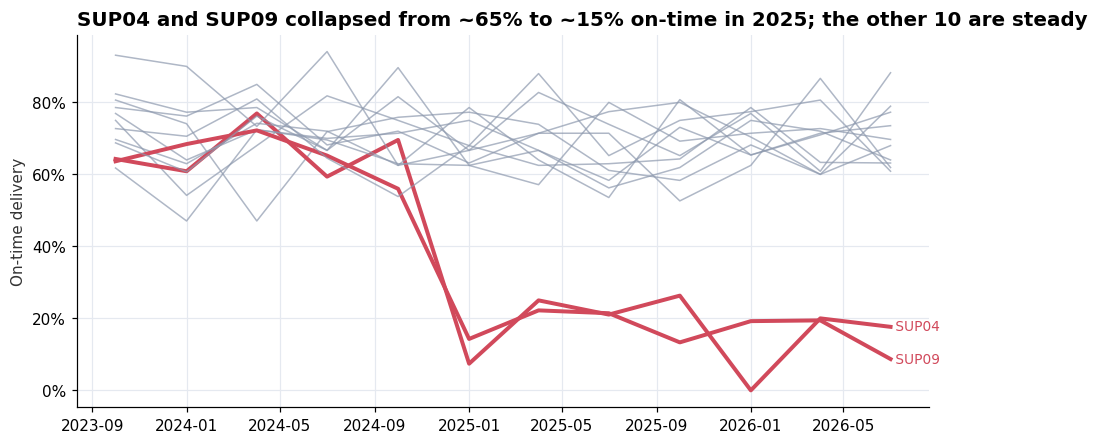

In [50]:
V.supplier_otd_trend_chart(R['supplier_trend'], ['SUP04','SUP09'])

In [51]:
R['materials'][['Material_Name','Spend','OTD','Lead_Time','Standard_Lead_Time','Reject_Rate','Price_Change_FY24_to_FY26','Products_Using','Coverage_vs_BOM','Criticality','Shortage_Risk']]

,Material_Name,Spend,OTD,Lead_Time,Standard_Lead_Time,Reject_Rate,Price_Change_FY24_to_FY26,Products_Using,Coverage_vs_BOM,Criticality,Shortage_Risk
5,Sewing Thread,"67,051,227.920",0.611,12.723,14,0.018,0.076,59.000,5.801,0.750,0.302
10,Water-Based Ink,"297,682,642.160",0.668,12.409,21,0.017,0.053,25.000,11.423,0.867,0.290
2,Rib Cotton,"97,389,898.900",0.673,12.489,10,0.017,0.084,16.000,0.639,0.637,0.212
7,Care Label,"10,342,353.870",0.689,12.639,14,0.018,0.046,59.000,0.360,0.650,0.208
1,Single Jersey Cotton 180 GSM,"95,957,491.920",0.685,11.911,14,0.017,0.033,15.000,0.793,0.650,0.198
0,Single Jersey Cotton 160 GSM,"83,881,844.010",0.664,11.857,10,0.018,0.067,15.000,0.577,0.512,0.166
6,Neck Label,"10,799,138.370",0.669,12.059,7,0.017,0.070,59.000,0.345,0.488,0.158
3,Summer Melton,"83,323,469.970",0.643,12.094,10,0.018,0.058,13.000,0.793,0.438,0.153
8,Poly Bag,"10,239,429.370",0.650,12.162,7,0.017,-0.007,59.000,0.351,0.438,0.151
11,Heat Transfer Film,"32,385,916.520",0.636,12.009,7,0.018,0.070,17.000,38.376,0.421,0.150


In [52]:
R['supplier_actions']

,Supplier_ID,Category,Contracted,OTD,Avg_Days_Late,Spend,Spend_Share,Reliability,Spend_Tier,Action
8,SUP09,Trims,No,0.346,3.619,"76,331,660.190",0.086,Unreliable,High spend,Replace or dual-source; put under contract
3,SUP04,Printing Consumables,Yes,0.399,2.918,"65,328,364.390",0.074,Unreliable,Lower spend,"Escalate: enforce contract SLA / penalties, qu..."
11,SUP12,Fabric,Yes,0.668,0.544,"61,850,511.200",0.070,Reliable,Lower spend,Monitor: tighten promised dates
5,SUP06,Packaging,Yes,0.679,0.481,"72,353,891.250",0.082,Reliable,Lower spend,Monitor: tighten promised dates
7,SUP08,Trims,No,0.690,0.491,"81,631,567.570",0.092,Reliable,High spend,Monitor: tighten promised dates
6,SUP07,Packaging,Yes,0.693,0.496,"84,758,330.190",0.096,Reliable,High spend,Monitor: tighten promised dates
0,SUP01,Packaging,No,0.703,0.477,"61,340,301.150",0.069,Reliable,Lower spend,Maintain; formalise contract
2,SUP03,Fabric,No,0.722,0.364,"82,890,481.050",0.094,Reliable,High spend,Maintain; formalise contract
4,SUP05,Fabric,No,0.724,0.397,"73,873,102.510",0.083,Reliable,Lower spend,Maintain; formalise contract
10,SUP11,Trims,Yes,0.725,0.446,"76,543,735.690",0.087,Reliable,High spend,Maintain / strategic partner


**Findings:** acceptance is uniform (reject ~1.8%); lead time ~12 days vs 11.5 promised. **SUP04 (OTD 40%, +2.9 days late) and SUP09 (35%, +3.6 days late)** collapsed in 2025; the other ten average 71%. OTIF (on time and <=2% rejects) is only ~35% in recent quarters. Input prices moved -1% to +8% between FY24 and FY26 (elastic band, rib cotton and thread up ~8%). Highest shortage risk: sewing thread (used in all 59 products), water-based ink, rib cotton. Purchases are mismatched with BOM requirements (ink 11x, film 38x, labels/poly bags ~35%) - likely LEO PRINT contract work and different units; validate.
**Action matrix:** SUP04 - enforce contract SLA + penalties, qualify a backup; SUP09 - no contract + 35% OTD -> replace/dual-source; SUP12/06/08/07 - tighten promised dates; others maintain; add safety stock for thread and ink until fixed.

## Case 10 - Integrated Management Story + Forecast

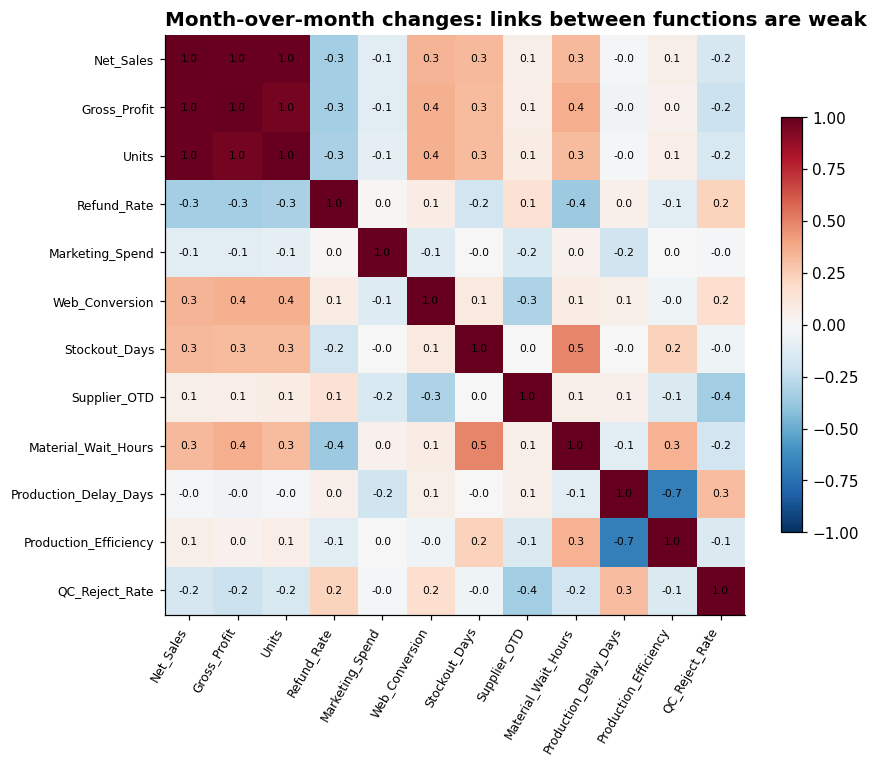

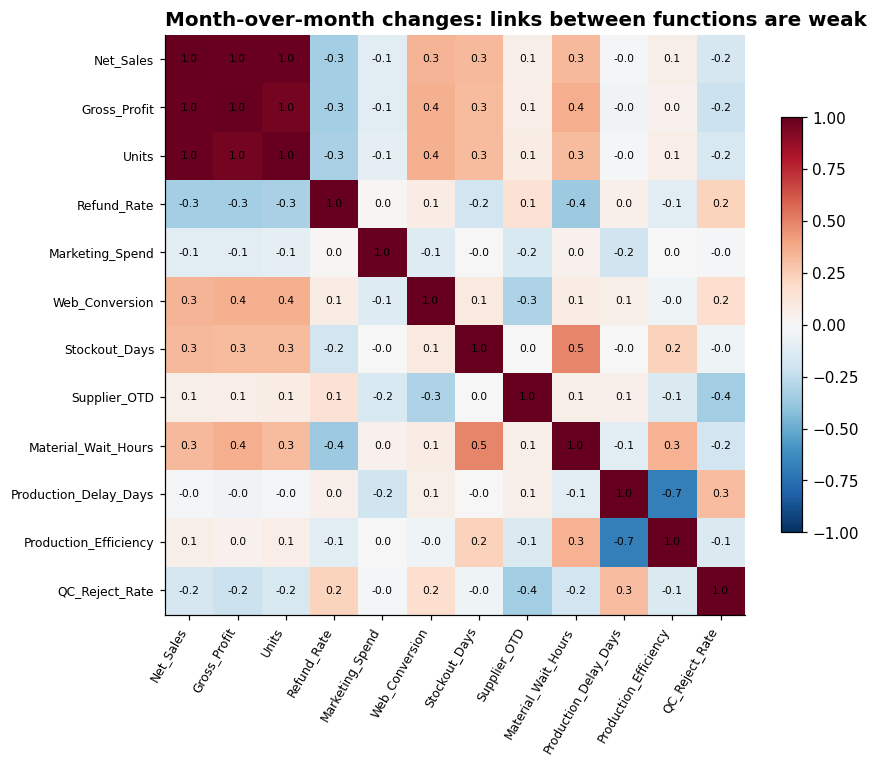

In [53]:
V.chain_corr_heatmap(R['chain_corr'])

In [54]:
R['fy27_base']

,Channel,Units,Net_Sales,Gross_Profit
0,Online,"45,879.371","14,934,124.935","5,169,507.818"
1,Retail,"26,850.884","9,116,595.180","3,372,614.236"
2,Wholesale,"534,602.670","129,882,439.726","15,433,088.364"


In [55]:
R['value_at_stake'][['Action','Lever','Low','Base','High','Assumption']]

,Action,Lever,Low,Base,High,Assumption
0,1. Wholesale discount governance - Phase 1: vo...,Margin,"2,850,815.251","3,866,768.186","4,882,721.120",Volume loss on re-priced lines 20% / 10% / 0%;...
1,1b. Wholesale discount governance - Phase 2: m...,Margin,"2,665,483.719","3,290,137.069","3,914,790.418","Incremental to Phase 1, same volume-loss assum..."
2,2. Win-back of lapsed high-frequency retail cu...,Revenue retention,"119,599.000","239,197.999","358,796.999",Reactivate 5% / 10% / 15% of the At-Risk (high...
3,3. Marketing reallocation (Influencer/Meta/Tik...,Efficiency,"-15,239.153","94,741.870","991,766.900",Google marginal ROAS = 25% / 50% / 100% of ave...
4,4. Cost of poor quality reduction,Cost,"544,097.138","1,088,194.275","1,632,291.413",QC-loss reduction 10% / 20% / 30%
5,5. Online size/fit return reduction,Margin,"14,686.988","24,478.314","39,165.302",Fewer size/fit returns 15% / 25% / 40% (size g...
6,6. Wholesale stockout recovery,Revenue retention,"90,617.554","181,235.109","271,852.663",Recover 25% / 50% / 75% of est. lost wholesale...


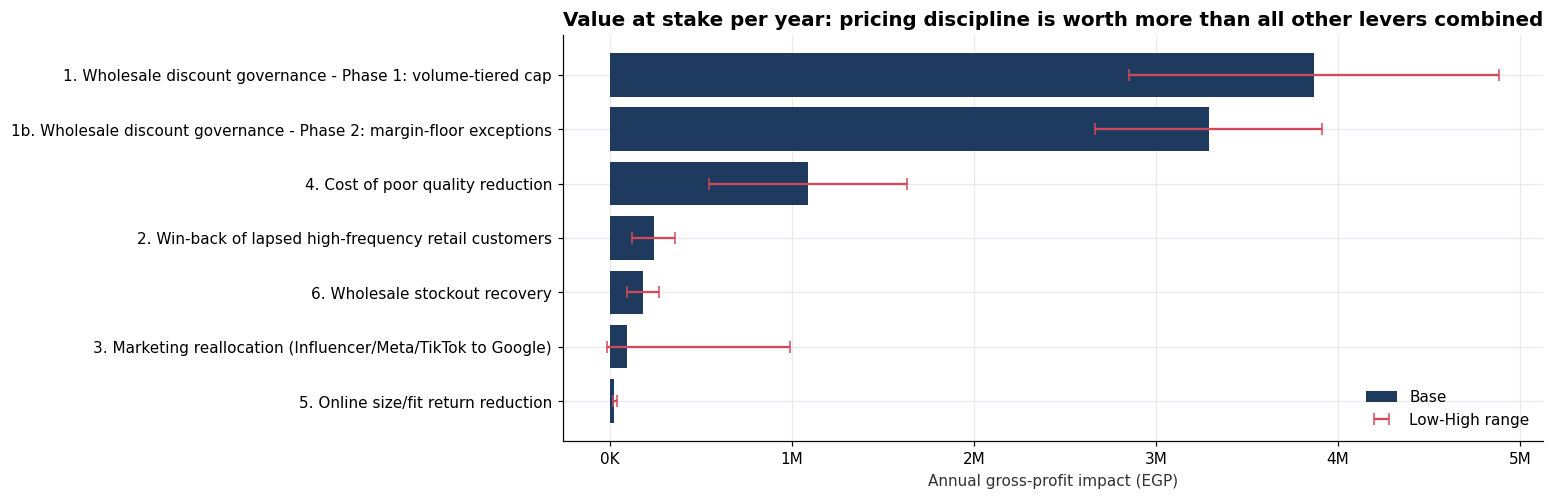

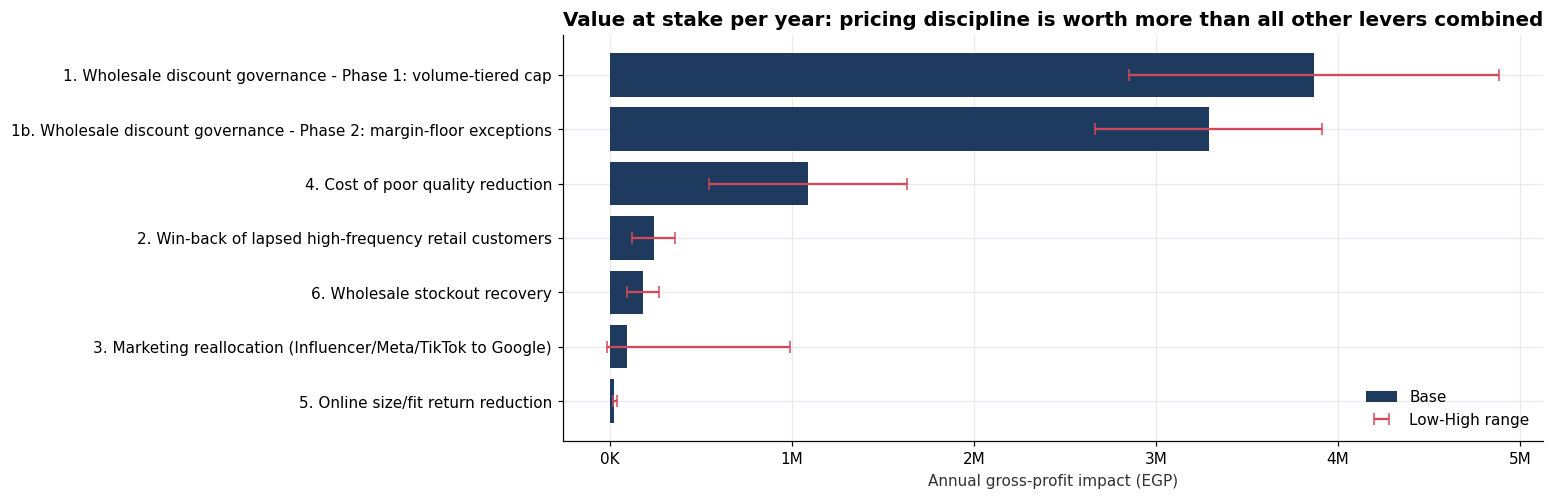

In [56]:
V.value_at_stake_chart(R['value_at_stake'])

**The connected story:** Demand is seasonal and two-speed (online +60%, wholesale +13%, retail -5%). Wholesale carries volume but is under-priced and under-stocked; retail/online carry the margin and the excess stock. The factory delivers on plan (91%) but delays come from Sewing/Finishing and LINE-04; supplier reliability is eroding in two named suppliers but is **not** (yet) the cause of delays; quality costs 31% of profit and is spread evenly (process control, not a single defect). Marketing efficiency is uneven but small in EGP terms compared with price discipline.

**Forecast / scenario assumptions:** base FY27 = 607K units, EGP 153.9M net sales, EGP 24.0M GP (+3.8% sales vs FY26) from the seasonal-index forecast at last-12-month prices. Value-at-stake low/base/high assumptions are listed per row above; base total ~EGP 8.8M GP per year (+38% of FY26 gross profit), of which 82% is wholesale pricing.